In [2]:
print("hello")

hello


Initializing the Project

In [3]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pywt

print("Libraries imported successfully!")

Libraries imported successfully!


Loading the Data

In [4]:
data_dir = Path(r"C:\Users\Asus\Downloads\ECG Dataset")

print("Dataset folder exists:", data_dir.exists())

if data_dir.exists():
    print("Files found:")
    for file in sorted(data_dir.iterdir())[:20]:
        print(file.name)

csv_files = sorted(data_dir.glob("*.csv"))

print("Total CSV files found:", len(csv_files))
print("First 10 files:", [f.name for f in csv_files[:10]])

Dataset folder exists: True
Files found:
100.csv
100annotations.txt
101.csv
101annotations.txt
102.csv
102annotations.txt
103.csv
103annotations.txt
104.csv
104annotations.txt
105.csv
105annotations.txt
106.csv
106annotations.txt
107.csv
107annotations.txt
108.csv
108annotations.txt
109.csv
109annotations.txt
Total CSV files found: 48
First 10 files: ['100.csv', '101.csv', '102.csv', '103.csv', '104.csv', '105.csv', '106.csv', '107.csv', '108.csv', '109.csv']


Checking the Data Loaded

In [5]:
file_path = data_dir / "100.csv"

df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

Dataset shape: (650000, 3)

First 5 rows:


,'sample #','MLII','V5'
0,0,995,1011
1,1,995,1011
2,2,995,1011
3,3,995,1011
4,4,995,1011



Column names:
["'sample #'", "'MLII'", "'V5'"]

Data types:
'sample #'    int64
'MLII'        int64
'V5'          int64
dtype: object


Cleaning the Data

In [6]:
print("Missing values per column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nInfinite values per column:")
print(
    np.isinf(df.select_dtypes(include=np.number)).sum()
)

print("\nStatistical summary:")
display(df.describe())

Missing values per column:
'sample #'    0
'MLII'        0
'V5'          0
dtype: int64

Duplicate rows: 0

Infinite values per column:
'sample #'    0
'MLII'        0
'V5'          0
dtype: int64

Statistical summary:


,'sample #','MLII','V5'
count,650000.000000,650000.000000,650000.000000
mean,324999.500000,962.740205,985.793114
std,187638.981824,38.639938,29.642668
min,0.000000,481.000000,531.000000
25%,162499.750000,946.000000,971.000000
50%,324999.500000,957.000000,983.000000
75%,487499.250000,970.000000,995.000000
max,649999.000000,1311.000000,1269.000000


Plotting the Input ECG Signal

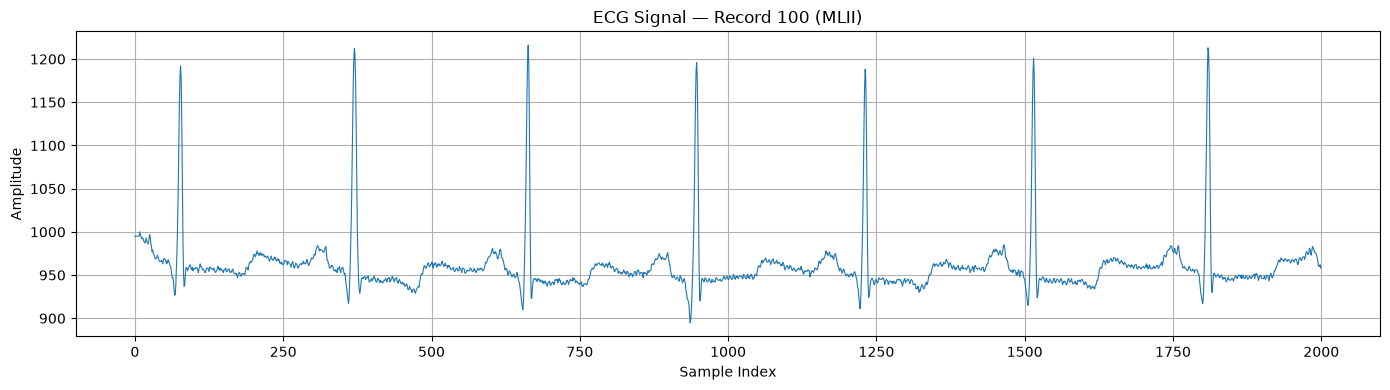

In [7]:
signal = pd.to_numeric(df["'MLII'"], errors="coerce")

# Plot the first 2000 samples
plt.figure(figsize=(14, 4))
plt.plot(signal.iloc[:2000], linewidth=0.8)

plt.title("ECG Signal — Record 100 (MLII)")
plt.xlabel("Sample Index")
plt.ylabel("Amplitude")
plt.grid(True)
plt.tight_layout()
plt.show()

In [8]:
signal = signal.interpolate(limit_area="inside")
signal = signal.replace([np.inf, -np.inf], np.nan)
signal = signal.dropna()

ecg_signal = signal.to_numpy(dtype=np.float64)

print("Total valid samples:", len(ecg_signal))
print("Signal mean:", np.mean(ecg_signal))
print("Signal standard deviation:", np.std(ecg_signal))

Total valid samples: 650000
Signal mean: 962.7402046153846
Signal standard deviation: 38.63990842744337


Normalizing the ECG Signal

Segment length: 1024


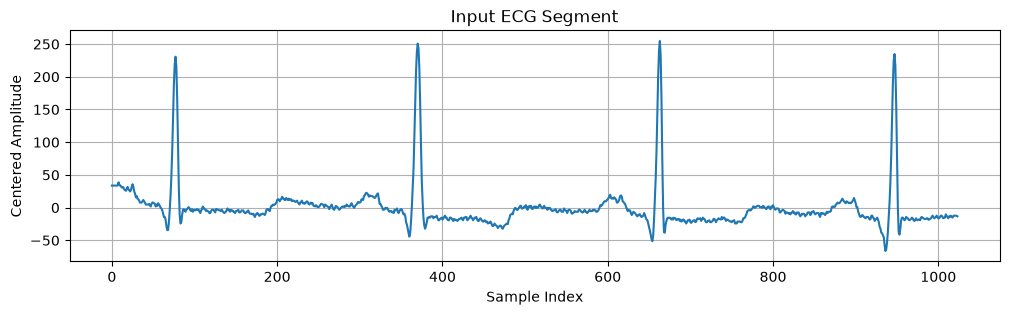

In [9]:
N = 1024

if len(ecg_signal) < N:
    raise ValueError("Not enough samples for the selected segment.")

x = ecg_signal[:N].copy()

# Center the segment
x = x - np.mean(x)

print("Segment length:", len(x))

plt.figure(figsize=(12, 3))
plt.plot(x)
plt.title("Input ECG Segment")
plt.xlabel("Sample Index")
plt.ylabel("Centered Amplitude")
plt.grid(True)
plt.show()

Applying DWT to the ECG Signal

In [10]:
wavelet = "db4"

coeffs = pywt.wavedec(
    x,
    wavelet=wavelet,
    mode="periodization",
    level=pywt.dwt_max_level(
        len(x), pywt.Wavelet(wavelet).dec_len
    )
)

# Combine all wavelet coefficient arrays
alpha = np.concatenate(coeffs)

print("Original signal length:", len(x))
print("Wavelet coefficient length:", len(alpha))
print("Wavelet decomposition levels:", len(coeffs) - 1)

Original signal length: 1024
Wavelet coefficient length: 1024
Wavelet decomposition levels: 7


Plottong the ECG Signal Obtained after the Wavelet Transform

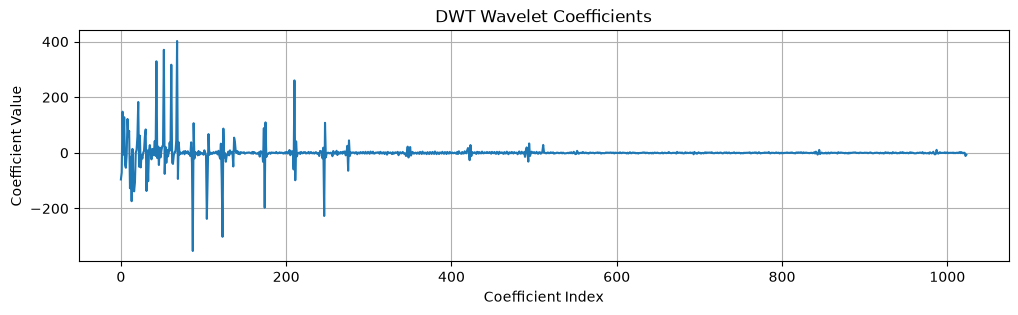

In [11]:
plt.figure(figsize=(12, 3))
plt.plot(alpha)
plt.title("DWT Wavelet Coefficients")
plt.xlabel("Coefficient Index")
plt.ylabel("Coefficient Value")
plt.grid(True)
plt.show()

Making the ECG Signal Obtained in the previous step Sparse

In [12]:
sparsity_fraction = 0.10

K = max(1, int(sparsity_fraction * len(alpha)))

# Indices of the K largest absolute coefficients
top_k_indices = np.argpartition(
    np.abs(alpha), -K
)[-K:]

alpha_sparse = np.zeros_like(alpha)
alpha_sparse[top_k_indices] = alpha[top_k_indices]

print("Total coefficients:", len(alpha_sparse))
print("Nonzero coefficients:", np.count_nonzero(alpha_sparse))
print("Sparsity:", 1 - np.count_nonzero(alpha_sparse) / len(alpha_sparse))

Total coefficients: 1024
Nonzero coefficients: 102
Sparsity: 0.900390625


Plotting the Sparse ECG Signal vs DWT Signal

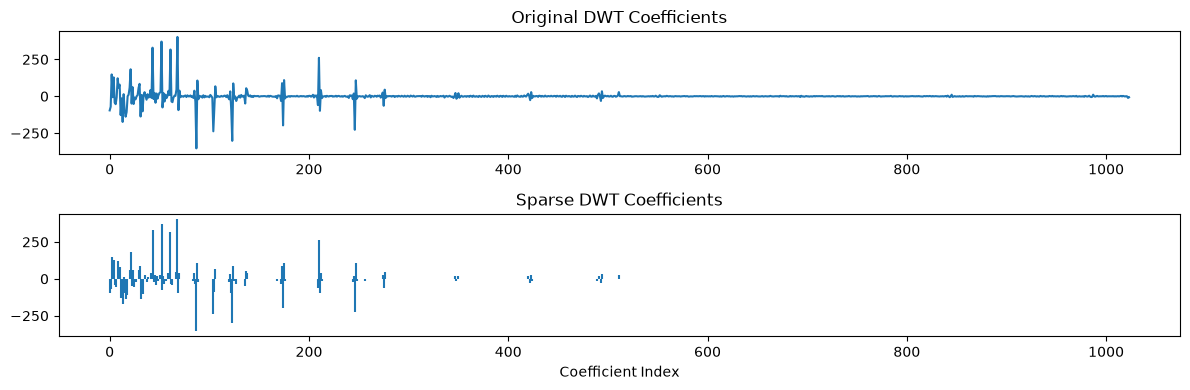

In [13]:
plt.figure(figsize=(12, 4))

plt.subplot(2, 1, 1)
plt.plot(alpha)
plt.title("Original DWT Coefficients")

plt.subplot(2, 1, 2)
plt.stem(alpha_sparse, markerfmt=" ", basefmt=" ")
plt.title("Sparse DWT Coefficients")
plt.xlabel("Coefficient Index")

plt.tight_layout()
plt.show()

Creating the Random Gaussian Matrix 

In [14]:
rng = np.random.default_rng(42)

M = 256  

Phi = rng.normal(
    loc=0.0,
    scale=1.0 / np.sqrt(M),
    size=(M, N)
)

print("Sensing matrix shape:", Phi.shape)

Sensing matrix shape: (256, 1024)


Multiplying the Gaussian Matrix with Sparse Signal to form the Compressed Signal

In [15]:
y = Phi @ alpha_sparse

print("Sparse coefficient vector shape:", alpha_sparse.shape)
print("Compressed measurement shape:", y.shape)
print(f"Measurement compression ratio: {N / M:.2f}:1")
print(f"Measurement reduction: {(1 - M / N) * 100:.1f}%")

Sparse coefficient vector shape: (1024,)
Compressed measurement shape: (256,)
Measurement compression ratio: 4.00:1
Measurement reduction: 75.0%


Plotting the Compressed Signal Obtained

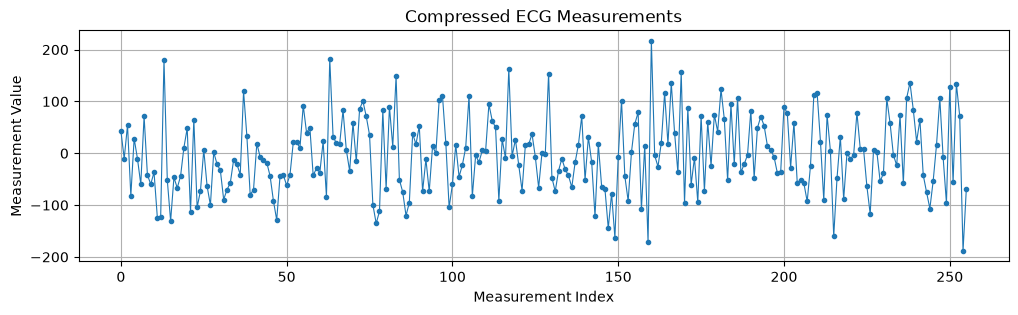

In [16]:
plt.figure(figsize=(12, 3))
plt.plot(y, marker=".", linewidth=0.8)
plt.title("Compressed ECG Measurements")
plt.xlabel("Measurement Index")
plt.ylabel("Measurement Value")
plt.grid(True)
plt.show()